<a href="https://colab.research.google.com/github/NaveenHerath/llm-from-scratch/blob/main/day7_model_with_attention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Bigram Model with Attention


In [3]:
#1. imports and variable setup
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

batch_size = 32       # B: chunks per batch
block_size = 8        # T: the longest context the model can see
n_embd = 32           # C: numbers describing each character
max_iters = 5000
eval_interval = 500
eval_iters = 200
learning_rate = 1e-3

In [4]:
#2. data and batches
!wget -q -nc https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]

def get_batch(split):
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    return x, y

In [5]:
#3. estimate loos
@torch.no_grad()
def estimate_loss(model):
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

In [6]:
#4.the attention head
class Head(nn.Module):
    """ one head of masked self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key   = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)                                       # (B, T, hs)
        q = self.query(x)                                     # (B, T, hs)
        wei = q @ k.transpose(-2, -1) * k.shape[-1]**-0.5     # (B, T, T), scaled
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        v = self.value(x)                                     # (B, T, hs)
        return wei @ v                                        # (B, T, hs)

In [7]:
#5.the model
class AttentionLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.sa_head = Head(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)                   # (B, T, C)
        pos_emb = self.position_embedding_table(torch.arange(T))    # (T, C)
        x = tok_emb + pos_emb                                       # (B, T, C)
        x = self.sa_head(x)                                         # (B, T, C)
        logits = self.lm_head(x)                                    # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            # crop to the last block_size characters: the position table
            # only has block_size rows, and the mask is block_size wide
            idx_cond = idx[:, -block_size:]
            logits, loss = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [8]:
#6.day 5 model for comparison
class BigramLanguageModel(nn.Module):      # your Day 5 model, for comparison

    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)
        if targets is None:
            return logits, None
        B, T, C = logits.shape
        loss = F.cross_entropy(logits.view(B*T, C), targets.view(B*T))
        return logits, loss

In [9]:
#7.training function for both models
def train(model):
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    history = []
    for step in range(max_iters + 1):
        if step % eval_interval == 0:
            l = estimate_loss(model)
            history.append((step, l['train'], l['val']))
            print(f"step {step:4d}: train {l['train']:.4f}, val {l['val']:.4f}")
        if step == max_iters:
            break
        xb, yb = get_batch('train')
        logits, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    return history

In [10]:
#8. train the bigram baseline
torch.manual_seed(1337)
bigram = BigramLanguageModel()
bigram_history = train(bigram)

step    0: train 4.7305, val 4.7241
step  500: train 4.1777, val 4.1811
step 1000: train 3.7309, val 3.7377
step 1500: train 3.3827, val 3.3909
step 2000: train 3.1246, val 3.1278
step 2500: train 2.9429, val 2.9429
step 3000: train 2.8009, val 2.8077
step 3500: train 2.7122, val 2.7127
step 4000: train 2.6468, val 2.6375
step 4500: train 2.5979, val 2.5999
step 5000: train 2.5601, val 2.5763


In [11]:
#9. train the model with baseline
torch.manual_seed(1337)
model = AttentionLanguageModel()
print(sum(p.numel() for p in model.parameters()), 'parameters')
history = train(model)

7553 parameters
step    0: train 4.2000, val 4.2047
step  500: train 2.6911, val 2.7087
step 1000: train 2.5196, val 2.5303
step 1500: train 2.4775, val 2.4829
step 2000: train 2.4408, val 2.4523
step 2500: train 2.4272, val 2.4435
step 3000: train 2.4130, val 2.4327
step 3500: train 2.3956, val 2.4212
step 4000: train 2.4041, val 2.3992
step 4500: train 2.3980, val 2.4084
step 5000: train 2.3946, val 2.4133


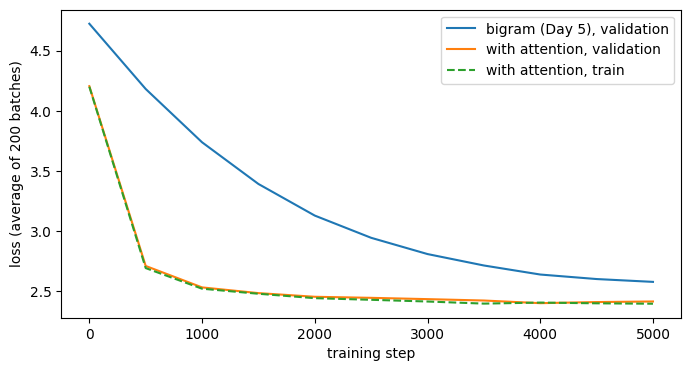

In [12]:
#10. save the loss curve
steps = [h[0] for h in history]
plt.figure(figsize=(8, 4))
plt.plot(steps, [h[2] for h in bigram_history], label='bigram (Day 5), validation')
plt.plot(steps, [h[2] for h in history], label='with attention, validation')
plt.plot(steps, [h[1] for h in history], '--', label='with attention, train')
plt.xlabel('training step')
plt.ylabel('loss (average of 200 batches)')
plt.legend()
plt.savefig('loss_curve_day07.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
#generate
torch.manual_seed(42)
start = torch.zeros((1, 1), dtype=torch.long)
print(decode(model.generate(start, max_new_tokens=300)[0].tolist()))


Mist quufe
Thaday at direr:
G al, otoutn bend fe tho erear heed lam:
Th,
Pre ot be
thall kungnl heere, thanou in
Lereier famendem:
I allly thalercilve whoughar ng ned I, wavine hefe, thoth.


OMI:' bors tho sdith hinove woun;
Moung;
Wer ut cacerit mny bef th ang wer
Pes
Torut wouck,
The, whe ancs br
